# Looking at FORGE waveforms with ObsPy

This notebook loads the event-windowed waveforms downloaded by `scripts/py/01_download_data.py`
and plots one event at all stations. It is the starting point for the cross-correlation step:
before measuring differential times we need to know what the arrivals look like.

**Inputs** (all in `data/raw_data/`):
- `catalog/…csv`: the Niemz et al. (2025) catalog (origin times, locations, magnitudes)
- `stations/stations.xml`: station metadata (coordinates, elevations, instrument responses)
- `waveforms/<ID>.mseed`: one miniSEED file per event, −5 s to +15 s around the origin time

Use the `python3` kernel from the project environment (`.loc`).

## 1. Imports and paths
- `obs.read` loads waveform files (miniSEED) into a `Stream`, a list of `Trace` objects (one per channel).
- `obs.read_inventory` loads StationXML metadata.
- `obs.UTCDateTime` is ObsPy's time type; subtracting two of them gives seconds.
- `obsgeo.gps2dist_azimuth` computes the distance (m) and azimuth between two lat/lon points on the ellipsoid.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import obspy as obs                   # obs.read, obs.read_inventory, obs.UTCDateTime
import obspy.geodetics as obsgeo      # obsgeo.gps2dist_azimuth

# Paths are relative to this notebook, which lives in notebooks/
DATA = Path("../data/raw_data")

## 2. Catalog and station metadata
The catalog `ID` column is zero-padded (`0001`), so read it as text, otherwise pandas turns it into
the number 1. Using `ID` as the index lets us look up an event with `cat.loc["0002"]`.

In [3]:
# Event catalog: one row per event
forge_catalog="microseismic_catalog_Utah_FORGE_2024stim_niemzetal2024.csv"
cat = pd.read_csv(DATA / "catalog" / forge_catalog,
                  dtype={"ID": str})      # keep "0001" as text, not the integer 1
cat = cat.set_index("ID")                # look up events by ID: cat.loc["0002"]

# Station metadata for all 18 stations (UU + 6K)
inv = obs.read_inventory(DATA / "stations" / "stations.xml")

cat.head()

,time(UTC),lat,lon,depth[m_local],east_shift[m_local],north_shift[m_local],magnitude,P_residual[s],S_residual[s],n_pairs,ndiff_p,ndiff_s
ID,,,,,,,,,,,,
0001,2024-04-03 17:47:29.411,38.50136,-112.88286,2427.85,1006.43,-200.84,-0.93,0.08,0.08,2879,8996,28539
0002,2024-04-03 17:47:40.372,38.50005,-112.88379,2498.85,924.98,-346.69,-0.49,0.10,0.08,2893,11025,32361
0003,2024-04-03 17:50:35.034,38.49988,-112.88379,2508.85,924.94,-365.61,-0.68,0.24,0.08,2875,12607,28642
0004,2024-04-03 17:52:17.349,38.50090,-112.88306,2428.85,988.88,-252.07,-0.75,0.11,0.08,2832,8015,29574
0005,2024-04-03 17:53:08.477,38.50002,-112.88379,2498.85,924.97,-350.03,-0.33,0.10,0.08,2877,10237,32885


Wrote /rcp/rcp42/home/esotelo/location_project/figures/station_map.png
  UU.FORK     0.9 km  near
  UU.FSB3     1.7 km  near
  6K.CS01     1.8 km  near
  UU.FSB2     1.8 km  near
  UU.FSB1     2.2 km  near
  UU.FOR2     2.3 km  near
  UU.NMU      4.3 km  far
  6K.CS05     5.2 km  far
  6K.CS04     5.3 km  far
  6K.CS02     5.6 km  far
  6K.CS06     5.7 km  far
  UU.FORU     5.9 km  far
  6K.CS03     5.9 km  far
  UU.FOR5     8.2 km  far
  UU.FSB4     9.3 km  far
  UU.FOR6     9.6 km  far
  UU.FOR7    10.0 km  far
  UU.FSB5    10.2 km  far


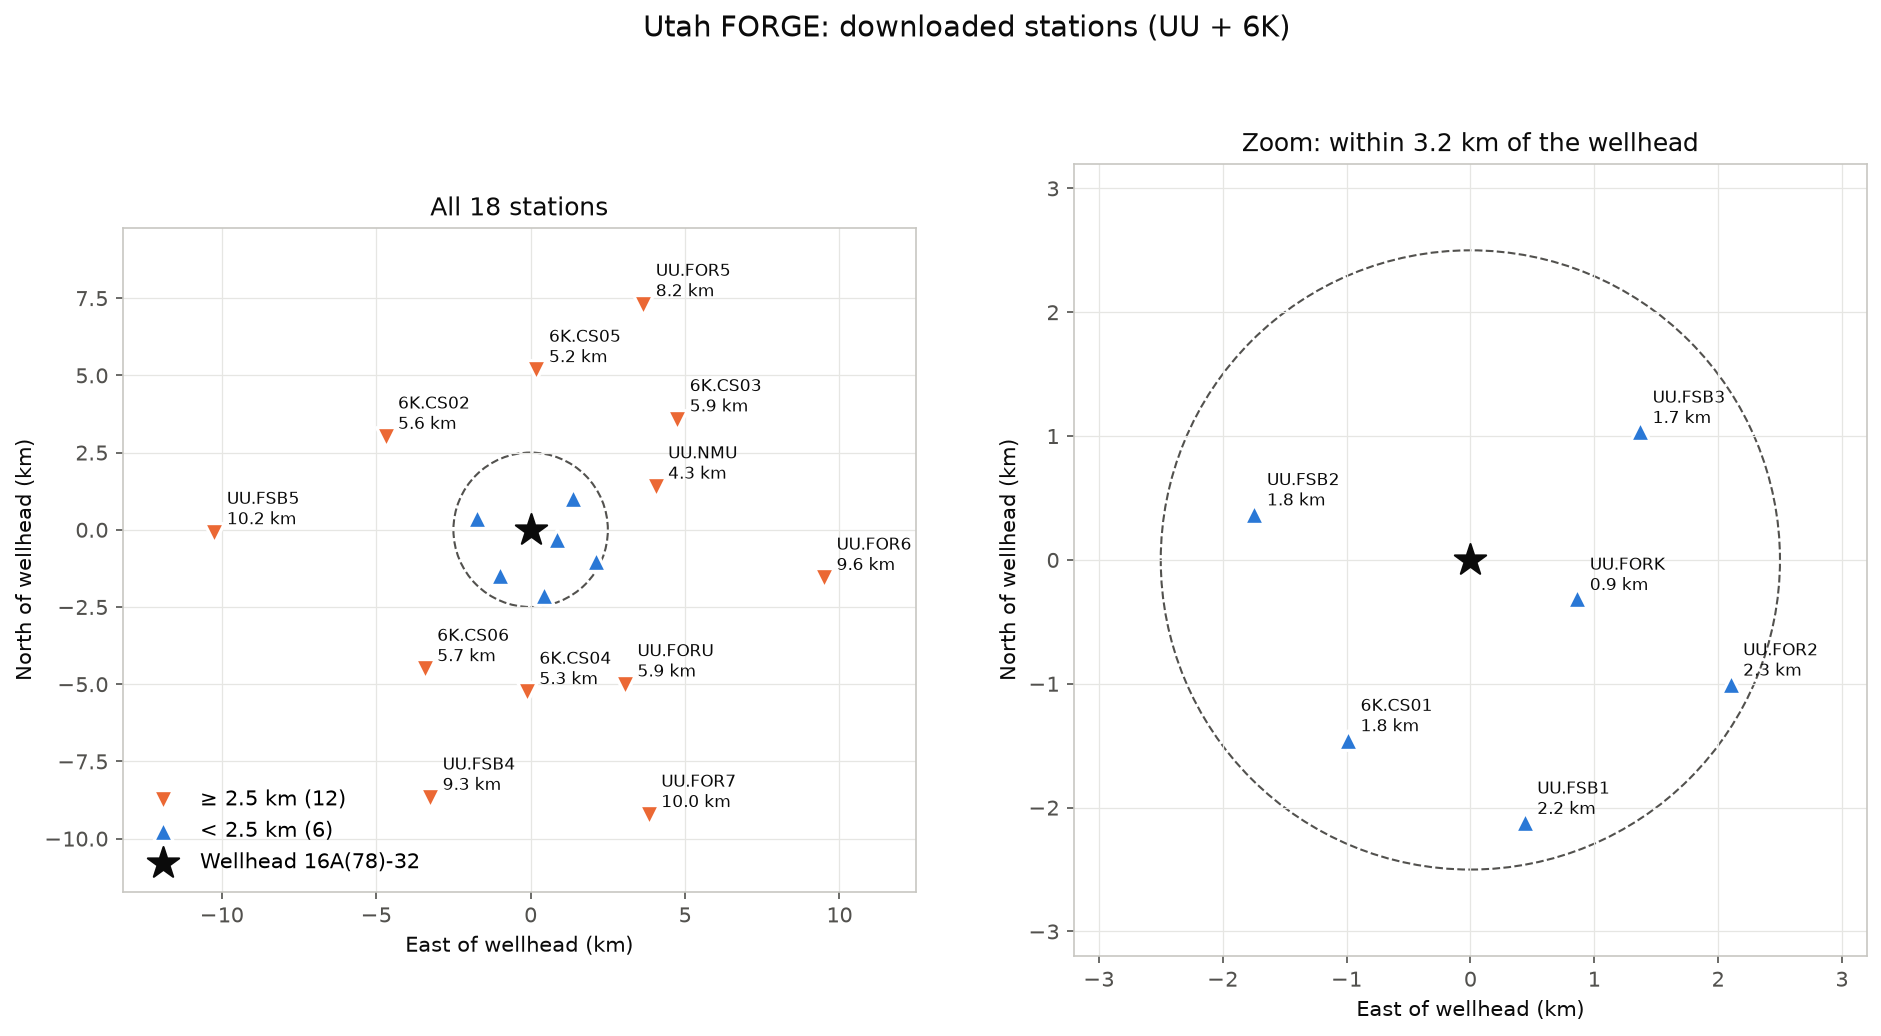

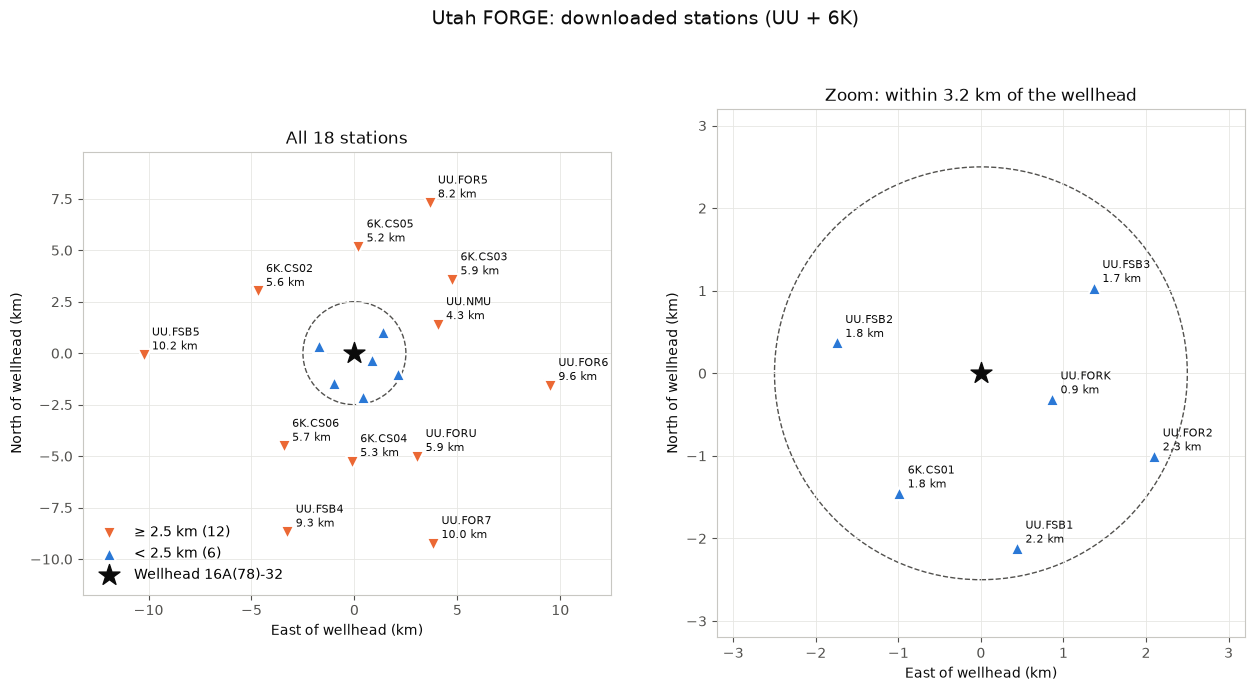

In [ ]:
#Plotting well head and stations location
%run ../scripts/py/plot_stations.py
from IPython.display import Image
Image("../figures/station_map.png")


## 3. Read one event's waveforms
Each event has its own file. `merge` joins traces that the data center split at small data gaps,
so we get exactly one trace per channel.

In [5]:
#example event 
#All 18 stations
evid = "0002"                              # event to look at; change this to explore others
ev = cat.loc[evid]                         # the catalog row for this event
origin = obs.UTCDateTime(ev["time(UTC)"])      # origin time as an ObsPy time

st = obs.read(DATA / "waveforms" / f"{evid}.mseed")   # Stream with all channels of this event
st.merge(fill_value=0)                    # one trace per channel (fill gaps with zeros)

print("origin:", origin, " magnitude:", ev["magnitude"], " depth (m):", ev["depth[m_local]"])
print(st.__str__(extended=True))         # list every trace, not only the first and last

origin: 2024-04-03T17:47:40.372000Z  magnitude: -0.49  depth (m): 2498.85
51 Trace(s) in Stream:
6K.CS01..GN1   | 2024-04-03T17:47:35.372000Z - 2024-04-03T17:47:55.372000Z | 1000.0 Hz, 20001 samples
6K.CS01..GN2   | 2024-04-03T17:47:35.372000Z - 2024-04-03T17:47:55.372000Z | 1000.0 Hz, 20001 samples
6K.CS01..GNZ   | 2024-04-03T17:47:35.372000Z - 2024-04-03T17:47:55.372000Z | 1000.0 Hz, 20001 samples
6K.CS02..GN1   | 2024-04-03T17:47:35.372000Z - 2024-04-03T17:47:55.372000Z | 1000.0 Hz, 20001 samples
6K.CS02..GN2   | 2024-04-03T17:47:35.372000Z - 2024-04-03T17:47:55.372000Z | 1000.0 Hz, 20001 samples
6K.CS02..GNZ   | 2024-04-03T17:47:35.372000Z - 2024-04-03T17:47:55.372000Z | 1000.0 Hz, 20001 samples
6K.CS03..GN1   | 2024-04-03T17:47:35.372000Z - 2024-04-03T17:47:55.372000Z | 1000.0 Hz, 20001 samples
6K.CS03..GN2   | 2024-04-03T17:47:35.372000Z - 2024-04-03T17:47:55.372000Z | 1000.0 Hz, 20001 samples
6K.CS03..GNZ   | 2024-04-03T17:47:35.372000Z - 2024-04-03T17:47:55.372000Z | 1000.0 Hz,

## 4. Selecting traces
`select` filters a Stream by network, station, location, channel or component. It returns the
**same** trace objects (not copies), so processing them also changes `st`.
`tr.stats` holds the header: station, channel, start time, sampling rate, number of samples.

3 Trace(s) in Stream:
UU.FORU.01.HHE | 2024-04-03T17:47:35.380000Z - 2024-04-03T17:47:55.370000Z | 100.0 Hz, 2000 samples
UU.FORU.01.HHN | 2024-04-03T17:47:35.380000Z - 2024-04-03T17:47:55.370000Z | 100.0 Hz, 2000 samples
UU.FORU.01.HHZ | 2024-04-03T17:47:35.380000Z - 2024-04-03T17:47:55.370000Z | 100.0 Hz, 2000 samples


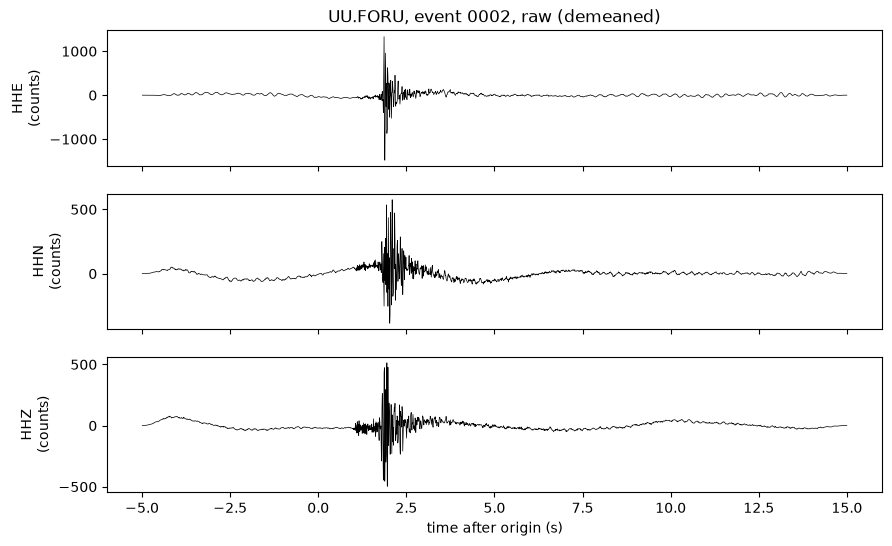

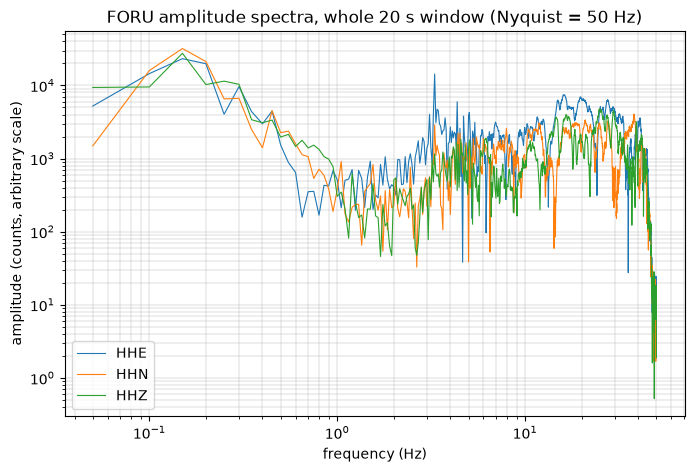

In [6]:
# All 3 components of one station: waveforms (1 figure) and amplitude spectra (1 figure)
sta = "FORU"
st_sta = st.select(station=sta).copy()        # copy: keep st raw
st_sta.detrend("demean")                     # remove offset
st_sta.taper(0.05)                           # smooth ends (also needed before the FFT)
print(st_sta)

# --- Waveforms: one panel per component, shared time axis ---
fig, axes = plt.subplots(len(st_sta), 1, figsize=(10, 6), sharex=True)
for ax, tr in zip(axes, st_sta):
    t = tr.times(reftime=origin)             # seconds after the catalog origin
    ax.plot(t, tr.data, "k", lw=0.5)
    ax.set_ylabel(f"{tr.stats.channel}\n(counts)")
axes[0].set_title(f"{tr.stats.network}.{sta}, event {evid}, raw (demeaned)")
axes[-1].set_xlabel("time after origin (s)")
plt.show()

# --- Amplitude spectra: all components in one plot ---
fig, ax = plt.subplots(figsize=(8, 5))
for tr in st_sta:
    amp = np.abs(np.fft.rfft(tr.data))                         # amplitude of each frequency
    freq = np.fft.rfftfreq(tr.stats.npts, d=tr.stats.delta)    # frequencies (Hz), 0 to Nyquist
    ax.loglog(freq[1:], amp[1:], lw=0.8, label=tr.stats.channel)   # skip 0 Hz (log axis)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("amplitude (counts, arbitrary scale)")
ax.set_title(f"{sta} amplitude spectra, whole 20 s window (Nyquist = {tr.stats.sampling_rate/2:g} Hz)")
ax.legend()
ax.grid(True, which="both", lw=0.3)
plt.show()

## 5. Pre-processing for Phase picking with PhaseNet
Same steps as `scripts/py/02_run_phasenet.py` (see `notes/processing_steps.md`, A2).
Always work on a **copy**, so `st` stays raw. All 3 components are kept (PhaseNet uses Z, N/1, E/2).
1. `detrend("demean")`: remove the constant offset (raw counts sit around a non-zero value).
2. `taper(0.05)`: smoothly bring the trace ends to zero (1 s at each end of our 20 s windows).
3. **Downsample to 100 Hz** (PhaseNet's rate):
   - **zero-phase low-pass at 40 Hz** (4 corners): anti-alias filter below the new Nyquist (50 Hz);
     `zerophase=True` so arrival times are **not shifted**;
   - **decimate**: keep every 2nd sample (200 Hz stations) or every 10th (1000 Hz: FORK, 6K).
     100 Hz stations (FORU, NMU) are left unchanged.
4. **Zero-pad to 40 s**: PhaseNet needs 30 s windows (3001 samples); our data are 20 s.
5. **No band-pass**: PhaseNet was trained on unfiltered data (the low-pass above is only anti-aliasing).

In [ ]:
#example with one event

TARGET_RATE = 100.0      # PhaseNet sampling rate (Hz)
ANTIALIAS_FREQ = 40.0    # low-pass corner (Hz), below the new Nyquist of 50 Hz
PAD_TO = 40.0            # padded window length (s)

st_pn = st.copy()                        # PhaseNet-ready stream, all components
st_pn.detrend("demean")                  # 1. remove the mean
st_pn.taper(0.05)                        # 2. 5 % cosine taper at each end

for tr in st_pn:                         # 3. downsample to 100 Hz
    sr = tr.stats.sampling_rate
    if sr == TARGET_RATE:
        continue                         #    FORU, NMU: already 100 Hz
    tr.filter("lowpass", freq=ANTIALIAS_FREQ, corners=4, zerophase=True)   # anti-alias, no time shift
    tr.decimate(int(sr // TARGET_RATE), no_filter=True)                     # keep every 2nd / 10th sample

half = PAD_TO / 2                        # 4. zero-pad around the centre of the 20 s window
st_pn.trim(origin + 5 - half, origin + 5 + half, pad=True, fill_value=0)

#print(st_pn.__str__(extended=True))      # all traces now 100 Hz, 40 s long

